# WHEN NATURE STRIKES
## 01 – Natural Disaster Frequency Analysis

### 1. Introduction

This analysis investigates the frequency and distribution
of different types of natural disasters recorded globally
in the EM-DAT dataset.

The objective is to identify which disaster types occur
most frequently and understand their contribution to
the overall number of recorded natural disaster events.

### 2. Research Questions

1. Which natural disaster type has the highest frequency?
2. Which disaster types contribute most to total events?
3. What percentage of total events does each disaster
   type represent?
4. How concentrated is the distribution among the
   most frequent disaster types?

### 3. Dataset

- Source: EM-DAT (CRED / UCLouvain)
- Main dataset: natural_disaster_events.csv
- Supporting dataset: natural_disaster_type_summary.csv
- Time coverage: 1900–2026
- Total unique events: 15,727

### 4. Methodology

- Use the event-level dataset.
- Group records by Disaster Type.
- Count distinct Event IDs.
- Calculate each disaster type's percentage
  contribution to total events.
- Verify calculated counts against the prepared
  disaster type summary.

### 5. Important Consideration

Each row in the event-level dataset represents one
underlying disaster event. Country-level impact records
are not counted as separate disaster events.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Identify the repository root

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"

# Load datasets

events = pd.read_csv(
    DATA_DIR / "natural_disaster_events.csv",
    encoding="utf-8-sig"
)

type_summary = pd.read_csv(
    DATA_DIR / "natural_disaster_type_summary.csv",
    encoding="utf-8-sig"
)

print("Datasets loaded successfully!")
print("Repository root:", ROOT)

Datasets loaded successfully!
Repository root: c:\Users\Shasa\Desktop\MINE\when-nature-strikes


In [8]:
### 6. Disaster Frequency Calculation

In [11]:
frequency_df["Cumulative Percentage"] = (
    frequency_df["Percentage"].cumsum()
).round(2)

display(frequency_df)

,Disaster Type,Unique Events,Percentage,Cumulative Percentage
0,Flood,5814,36.97,36.97
1,Storm,4026,25.60,62.57
2,Earthquake,1573,10.00,72.57
3,Epidemic,1447,9.20,81.77
4,Mass movement (wet),867,5.51,87.28
5,Drought,647,4.11,91.39
6,Wildfire,508,3.23,94.62
7,Extreme temperature,433,2.75,97.37
8,Volcanic activity,277,1.76,99.13
9,Infestation,78,0.50,99.63


In [12]:
verification = frequency_df.merge(
    type_summary[["Disaster Type", "Unique Events"]],
    on="Disaster Type",
    how="outer",
    suffixes=("_Calculated", "_Summary"),
    validate="one_to_one"
)

verification["Match"] = (
    verification["Unique Events_Calculated"]
    == verification["Unique Events_Summary"]
)

display(verification)

print(
    "All disaster frequency counts match:",
    verification["Match"].all()
)

,Disaster Type,Unique Events_Calculated,Percentage,Cumulative Percentage,Unique Events_Summary,Match
0,Animal incident,1,0.01,99.98,1,True
1,Drought,647,4.11,91.39,647,True
2,Earthquake,1573,10.00,72.57,1573,True
3,Epidemic,1447,9.20,81.77,1447,True
4,Extreme temperature,433,2.75,97.37,433,True
5,Flood,5814,36.97,36.97,5814,True
6,Fog,1,0.01,99.99,1,True
7,Glacial lake outburst flood,7,0.04,99.97,7,True
8,Impact,1,0.01,100.00,1,True
9,Infestation,78,0.50,99.63,78,True


All disaster frequency counts match: True


In [13]:
#Graph 1 — Disaster frequency ranking

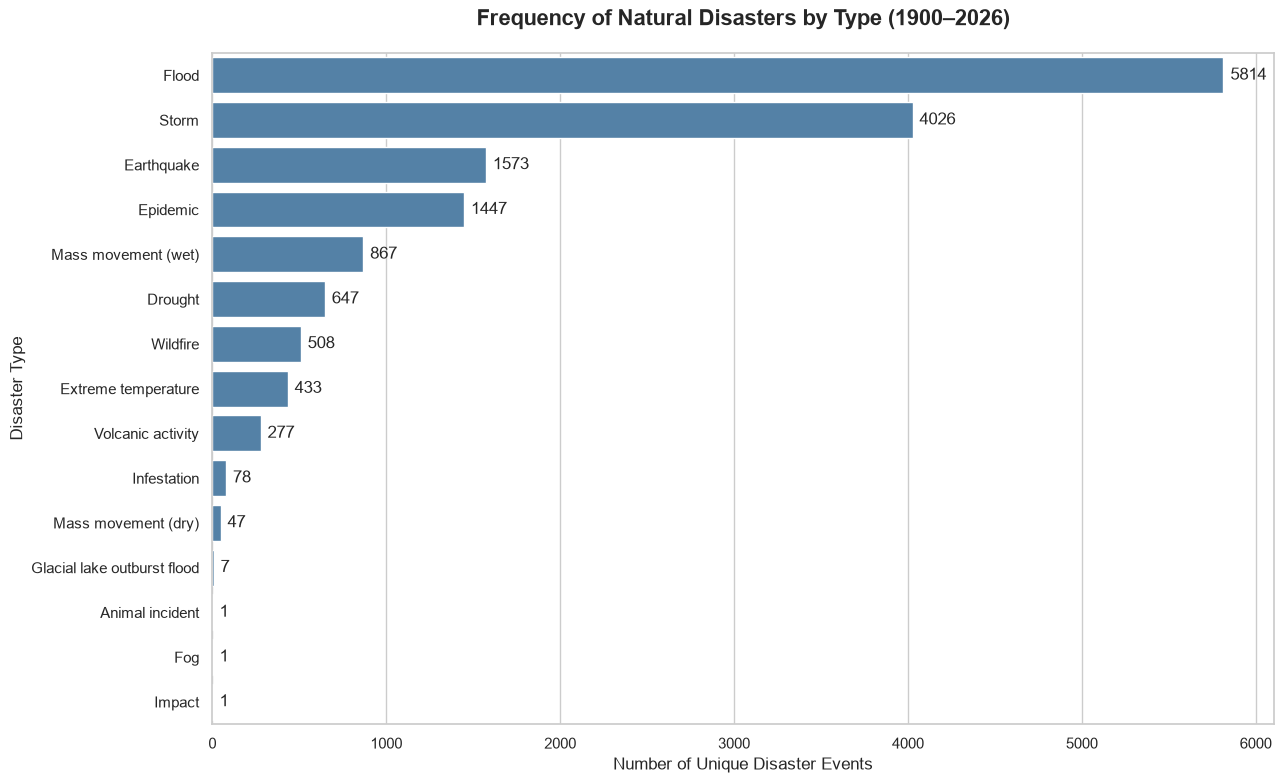

In [14]:
# Create output directory
output_dir = ROOT / "visualizations" / "frequency"
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=frequency_df,
    x="Unique Events",
    y="Disaster Type",
    color="steelblue"
)

# Add values beside each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5)

plt.title(
    "Frequency of Natural Disasters by Type (1900–2026)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Number of Unique Disaster Events")
plt.ylabel("Disaster Type")

plt.tight_layout()

plt.savefig(
    output_dir / "01_disaster_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
#Graph 2 — Cumulative frequency distribution

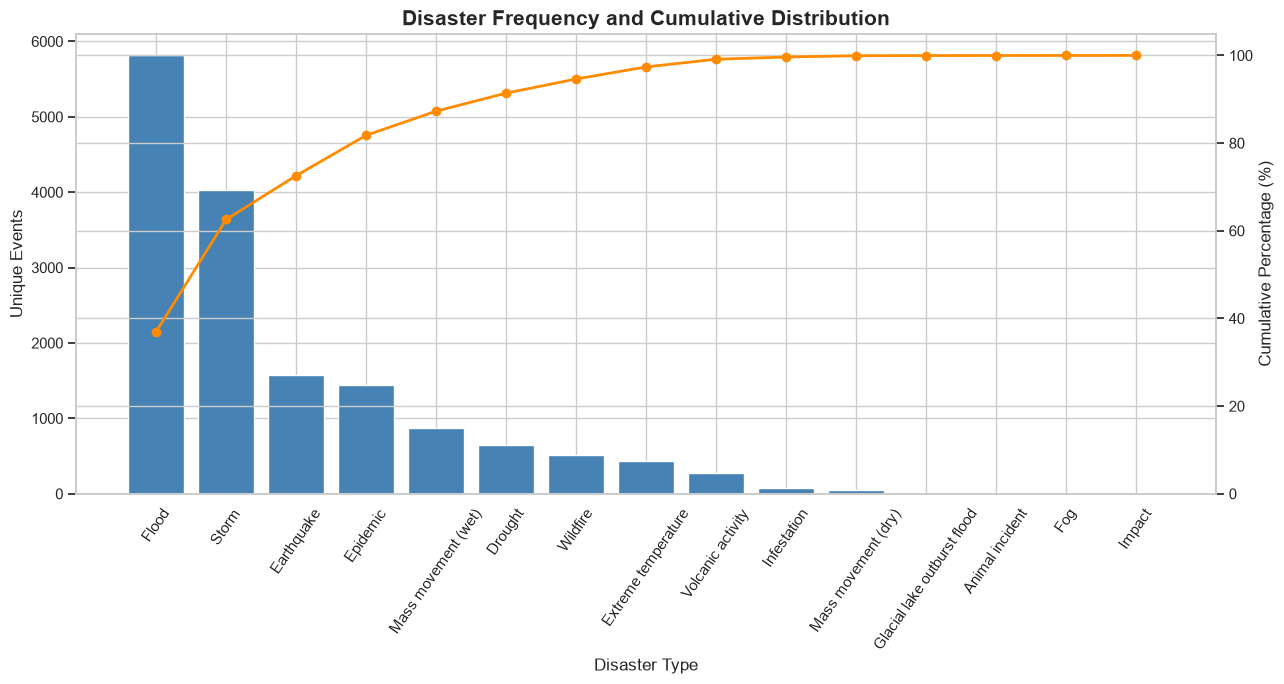

In [16]:
fig, ax1 = plt.subplots(figsize=(13, 7))

ax1.bar(
    frequency_df["Disaster Type"],
    frequency_df["Unique Events"],
    color="steelblue"
)

ax1.set_xlabel("Disaster Type")
ax1.set_ylabel("Unique Events")
ax1.set_title(
    "Disaster Frequency and Cumulative Distribution",
    fontsize=15,
    fontweight="bold"
)

ax1.tick_params(axis="x", rotation=55)

ax2 = ax1.twinx()

ax2.plot(
    frequency_df["Disaster Type"],
    frequency_df["Cumulative Percentage"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

ax2.set_ylabel("Cumulative Percentage (%)")
ax2.set_ylim(0, 105)

plt.tight_layout()

plt.savefig(
    output_dir / "02_cumulative_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
top_5 = frequency_df.head(5)

top_2_percentage = frequency_df.head(2)["Percentage"].sum()

print("TOP 5 MOST FREQUENT DISASTERS")
display(top_5)

print("\nTOTAL UNIQUE EVENTS:", total_events)

print(
    "\nFlood and Storm combined contribution:",
    round(top_2_percentage, 2), "%"
)

print(
    "\nMost frequent disaster:",
    frequency_df.iloc[0]["Disaster Type"]
)

print(
    "Least frequent disaster:",
    frequency_df.iloc[-1]["Disaster Type"]
)

TOP 5 MOST FREQUENT DISASTERS


,Disaster Type,Unique Events,Percentage,Cumulative Percentage
0,Flood,5814,36.97,36.97
1,Storm,4026,25.60,62.57
2,Earthquake,1573,10.00,72.57
3,Epidemic,1447,9.20,81.77
4,Mass movement (wet),867,5.51,87.28



TOTAL UNIQUE EVENTS: 15727

Flood and Storm combined contribution: 62.57 %

Most frequent disaster: Flood
Least frequent disaster: Impact
